## Implmenentación del Modelo oculto de Markov (HMM)


Un Modelo Oculto de Markov es un modelo probabilístico diseñado para analizar datos secuenciales o series temporales. Asume que el sistema estudiado cambia entre varios estados no observables directamente (ocultos) a lo largo del tiempo, y que en cada instante $t$, el estado oculto $S_t$ genera una observación visible $X_t$.

---
#### Características de este trabajo:
- **Estados Ocultos ($S_t$)**: Representan la condición de riesgo de la red (por ejemplo, Normal, Escaneo/Reconocimiento, Acceso Inicial o Exfiltración/Crítico). No conocemos directamente en qué estado está la red fila a fila sin inspección forense.

- **Observaciones Visibles ($X_t$)**: Son las métricas continuas del flujo extraídas del tráfico de red (Flow Duration, Tot Fwd Pkts, Tot Bwd Pkts).

- **Mecanismo de Aprendizaje (No Supervisado)**: Mediante el algoritmo de Baum-Welch (Expectation-Maximization), el HMM ajusta sus parámetros aprendiendo cómo cambia el tráfico paso a paso ($X_t \to X_{t+1}$) dentro de cada sesión (Src IP, Dst IP). 

In [1]:
#dependencias
import pandas as pd
from hmmlearn import hmm

### Cargo los archivos `.csv`

In [2]:
secuencias = pd.read_csv("../datos/secuencias.csv").values
long_sec = pd.read_csv("../datos/longitud_secuencias.csv")['longitud'].tolist()
df_original = pd.read_csv("../datos/original_ordenado.csv")

### Configuración del Modelo (GaussianHMM)

Se instanció un ``GaussianHMM`` fijando $N = 4$ componentes (estados ocultos), una matriz de covarianza completa (``covariance_type="full"``) para capturar la correlación entre las 3 métricas continuas, y una semilla aleatoria (``random_state=42``) para garantizar la reproducibilidad de los resultados.

In [3]:
#Instanciar el HMM con 4 estados

model_4states = hmm.GaussianHMM(
    n_components=4, 
    covariance_type="full", 
    n_iter=300, 
    random_state=42
)

#### Ajuste y Predicción de Estados Ocultos

- Entrenamiento (``model.fit``): Se ajusta el HMM pasándole la matriz $X$ y el vector lengths. La inclusión de ``lengths`` informa explícitamente a hmmlearn dónde inicia y termina cada sesión entre pares de IP, evitando que el modelo asuma falsas transiciones entre dispositivos distintos.

- Inferencia de Estados (``model.predict``): Utiliza el algoritmo de Viterbi para deducir la secuencia de estados ocultos más probable para cada registro del dataset y la asigna a la columna ``Estado_HMM``.  

In [4]:
#ajustar informando la estructura de secuencias
model_4states.fit(secuencias, lengths=long_sec)

#predecir los estados ocultos para cada registro
hidden_states_4 = model_4states.predict(secuencias, lengths=long_sec)

#agregar al dataframe original las predicciones
df_original['Estado_HMM'] = hidden_states_4

Model is not converging.  Current: 8088485.028693457 is not greater than 8088506.959409713. Delta is -21.930716255679727


In [5]:
df_original.head()

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Src IP,Dst IP,Timestamp,Label,Estado_HMM
0,2867254,1,1,0.0.0.0,255.255.255.255,2025-04-23 12:35:35,Exfiltration,1
1,438769,1,1,0.0.0.0,255.255.255.255,2025-04-24 16:01:09,Lateral movement,1
2,18,3,1,10.0.2.15,10.0.2.3,2025-04-17 15:42:26,Initial access,1
3,11,3,1,10.0.2.15,10.0.2.3,2025-04-17 15:42:30,Initial access,1
4,5006219,7,1,10.0.2.15,10.0.2.3,2025-04-17 15:42:32,Initial access,1


## Resultados

In [6]:
# Ver distribución de los 4 estados
print("--- Cantidad de registros por Estado HMM ---")
print(df_original['Estado_HMM'].value_counts())

--- Cantidad de registros por Estado HMM ---
Estado_HMM
0    428887
1     65093
3     48830
2     11669
Name: count, dtype: int64


#### Mapeo y Caracterización de Estados con Label

Se genera la tabla cruzada de frecuencias relativas (``pd.crosstab`` con Label) para interpretar el perfil operacional de los 4 estados identificados por el modelo no supervisado:

- Estado 0: Reconnaissance.

- Estado 1: Initial Access

- Estado 2: Concentra eventos de Exfiltration ($43.13\%$) y Benign

- Estado 3: Presenta una mezcla de Initial Access ($35.50\%$), Reconnaissance ($31.73\%$) y Lateral Movement ($19.53\%$).  

In [7]:
# Matriz de confusión / Frecuencias relativas con Label
print("\n--- Distribución de Label real en los 4 Estados HMM (%) ---")
tabla_4 = pd.crosstab(df_original['Estado_HMM'], df_original['Label'], normalize='index') * 100
print(tabla_4.round(2))


--- Distribución de Label real en los 4 Estados HMM (%) ---
Label       Benign  Exfiltration  Initial access  Lateral movement  \
Estado_HMM                                                           
0             0.41          2.94            8.34              0.07   
1            10.76          3.13           73.85              3.97   
2            28.49         43.13            7.82              0.75   
3             0.49         12.74           35.50             19.53   

Label       Reconnaissance  
Estado_HMM                  
0                    88.24  
1                     8.29  
2                    19.81  
3                    31.73  


#### Extracción de la Matriz de Transición ($A$)

Se extrae la propiedad ``model_4states.transmat_`` del modelo entrenado. Esta matriz de $4 \times 4$ representa la probabilidad de dinámica temporal entre los distintos niveles de riesgo de la red y constituye el parámetro de entrada principal para conectar con los módulos de Teoría de Decisiones, Juegos, Colas e Inventarios.

In [8]:
# Matriz de Transición A (4x4)
df_trans_4 = pd.DataFrame(
    model_4states.transmat_,
    columns=['E0', 'E1', 'E2', 'E3'],
    index=['E0', 'E1', 'E2', 'E3']
)
print("\n--- Matriz de Transición A (4x4) ---")
print(df_trans_4.round(4))# Matriz de Transición A (4x4)
df_trans_4 = pd.DataFrame(
    model_4states.transmat_,
    columns=['E0', 'E1', 'E2', 'E3'],
    index=['E0', 'E1', 'E2', 'E3']
)


--- Matriz de Transición A (4x4) ---
        E0      E1      E2      E3
E0  0.9716  0.0015  0.0053  0.0216
E1  0.0091  0.9391  0.0022  0.0495
E2  0.1948  0.0101  0.7854  0.0098
E3  0.1903  0.0656  0.0023  0.7418


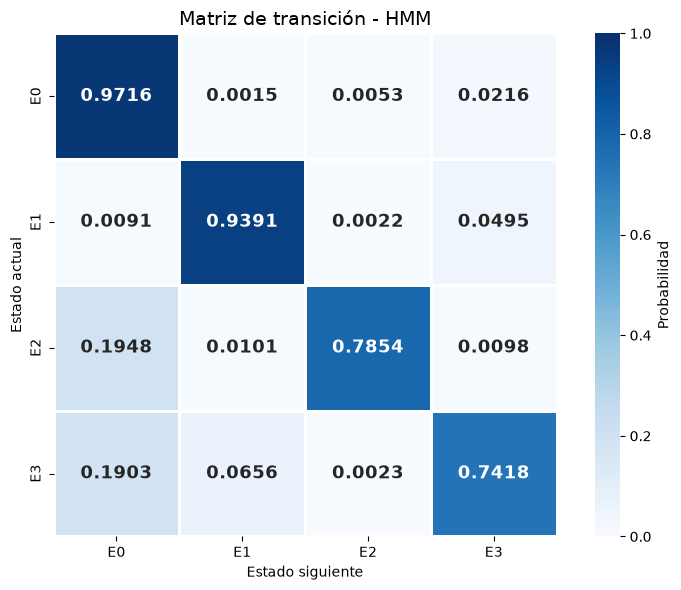

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    df_trans_4,
    annot=True,
    fmt='.4f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor='white',
    square=True,
    cbar_kws={'label': 'Probabilidad'},
    annot_kws={"size": 13, "weight": "bold"}
)

plt.title('Matriz de transición - HMM', fontsize=14)
plt.xlabel('Estado siguiente')
plt.ylabel('Estado actual')
plt.tight_layout()
plt.savefig('../img/matriz_transicion_hmm.png', transparent=True, dpi=300)
plt.show()

In [9]:
import json

# Guardamos la matriz de transición junto con metadata útil para los siguientes notebooks
datos_hmm = {
    "estados": ["E0", "E1", "E2", "E3"],
    "descripcion_estados": {
        "E0": "Reconnaissance",
        "E1": "Initial Access",
        "E2": "Exfiltration (Estado Crítico)",
        "E3": "Pivote / Transición"
    },
    "matriz_transicion": model_4states.transmat_.tolist(),
    "probabilidades_iniciales": model_4states.startprob_.tolist()
}

with open("../datos_procesados/resultados_hmm.json", "w", encoding="utf-8") as f:
    json.dump(datos_hmm, f, indent=4)

print("Matriz exportada exitosamente a ../datos_procesados/resultados_hmm.json")

Matriz exportada exitosamente a ../datos_procesados/resultados_hmm.json
